# The Huang Scares: source data analysis
### The Yariverse: Published aggregate data, reproducible calculations and charts

## Summary
- In Johnson et al. (2010), Study 1 Table 3, the higher minus lower attractiveness difference for women is **−0.16 standardized rating units** in masculine jobs where appearance is unimportant; it is positive in the other three contexts.
- The 2021 scientists’ survey reports a **39.0 percentage point** gap in surveillance fear (50.7% versus 11.7%).
- The 2023 scoping review contains **15 qualitative and 8 quantitative studies**. Theme counts describe studies, not the proportion of women experiencing discrimination.

## Context and methods
This analyzes published aggregate results from sources cited in the supplied essay. Values were manually transcribed from linked primary publications and checked on November 16th, 2026. No synthetic respondents or estimated hiring rates are used. Dependencies: Python 3, pandas, numpy, matplotlib and IPython. Run all cells; exports go to the current folder.

### Key assumptions and limits
Survey percentages are rounded published values; subgroup denominators and survey design are unavailable in the selected release, so no confidence intervals or significance tests are inferred. Johnson’s rows summarize photographs rated across repeated job contexts, not independent hiring decisions. Calculated differences use rounded published means; they are not Cohen’s d. No new p values are calculated. The paper’s prose appears to swap two means in the post-hoc paragraph; this notebook follows the explicit labels in Table 3. Findings predate and cannot establish effects of the draft’s unverified 2026 controversy.

The original concept map and document are retained in the HTML beneath the new analytical section.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64, html, json
from IPython.display import display, Image
OUTPUT_DIR = Path('.')
P = {'baby':'#C9DFF2','ivory':'#F7F3E8','slate':'#293D52','dusty':'#A9B8C5'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'text.color':P['slate'], 'axes.labelcolor':P['slate'], 'xtick.color':P['slate'], 'ytick.color':P['slate'], 'svg.fonttype':'none'})
SOURCES = {
 'johnson2010': {'url':'https://www.tandfonline.com/doi/pdf/10.1080/00224540903365414','location':'Study 1, Table 3, p. 309','unit':'mean standardized employment-suitability rating'},
 'c1002021': {'url':'https://www.committee100.org/media-center/new-research-reveals-racial-profiling-among-scientists-of-chinese-descent-and-the-consequences-for-the-u-s-scientific-community/','location':'Key data points; summer 2021 survey; total sample 1,949','unit':'percent of responding group; item-specific denominators unavailable'},
 'forbes2023': {'url':'https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2023.993396/full','location':'Results: Study characteristics; Qualitatively defining intersectional discrimination','unit':'number of studies'},
 'hosoda2003': {'url':'https://stars.library.ucf.edu/scopus2000/2174/','location':'Author-affiliated university repository abstract; DOI 10.1111/j.1744-6570.2003.tb00157.x','unit':'published weighted mean standardized effect size d'}
}
display(pd.DataFrame(SOURCES).T)


,url,location,unit
johnson2010,https://www.tandfonline.com/doi/pdf/10.1080/00...,"Study 1, Table 3, p. 309",mean standardized employment-suitability rating
c1002021,https://www.committee100.org/media-center/new-...,Key data points; summer 2021 survey; total sam...,percent of responding group; item-specific den...
forbes2023,https://www.frontiersin.org/journals/public-he...,Results: Study characteristics; Qualitatively ...,number of studies
hosoda2003,https://stars.library.ucf.edu/scopus2000/2174/,Author-affiliated university repository abstra...,published weighted mean standardized effect si...


## Data
### Published suitability ratings
All 16 cells of Johnson et al. Study 1 Table 3. `n_photos` is the number of photographs in each sex–attractiveness group; the same photographs recur across job contexts.

In [4]:
rows = [
('Male','Low','Masculine','Low',-.13,.41,49),('Male','Low','Masculine','High',-.33,.45,49),('Male','Low','Feminine','Low',-.39,.43,49),('Male','Low','Feminine','High',-.40,.34,49),
('Male','High','Masculine','Low',.25,.35,53),('Male','High','Masculine','High',.32,.45,53),('Male','High','Feminine','Low',.05,.48,53),('Male','High','Feminine','High',.21,.33,53),
('Female','Low','Masculine','Low',.01,.23,53),('Female','Low','Masculine','High',-.30,.36,53),('Female','Low','Feminine','Low',-.08,.34,53),('Female','Low','Feminine','High',-.33,.36,53),
('Female','High','Masculine','Low',-.15,.28,49),('Female','High','Masculine','High',.30,.36,49),('Female','High','Feminine','Low',.41,.36,49),('Female','High','Feminine','High',.54,.33,49)]
ratings = pd.DataFrame(rows,columns=['sex','attractiveness','job_type','appearance_importance','mean','sd','n_photos'])
ratings['source_id']='johnson2010'
ratings['source_url']=SOURCES['johnson2010']['url']
ratings['source_location']='Study 1 Table 3'
ratings['context']=ratings.job_type+' / appearance '+ratings.appearance_importance.str.lower()
display(ratings.drop(columns=['source_url']).round(2))


,sex,attractiveness,job_type,appearance_importance,mean,sd,n_photos,source_id,source_location,context
0,Male,Low,Masculine,Low,-0.13,0.41,49,johnson2010,Study 1 Table 3,Masculine / appearance low
1,Male,Low,Masculine,High,-0.33,0.45,49,johnson2010,Study 1 Table 3,Masculine / appearance high
2,Male,Low,Feminine,Low,-0.39,0.43,49,johnson2010,Study 1 Table 3,Feminine / appearance low
3,Male,Low,Feminine,High,-0.40,0.34,49,johnson2010,Study 1 Table 3,Feminine / appearance high
4,Male,High,Masculine,Low,0.25,0.35,53,johnson2010,Study 1 Table 3,Masculine / appearance low
5,Male,High,Masculine,High,0.32,0.45,53,johnson2010,Study 1 Table 3,Masculine / appearance high
6,Male,High,Feminine,Low,0.05,0.48,53,johnson2010,Study 1 Table 3,Feminine / appearance low
7,Male,High,Feminine,High,0.21,0.33,53,johnson2010,Study 1 Table 3,Feminine / appearance high
8,Female,Low,Masculine,Low,0.01,0.23,53,johnson2010,Study 1 Table 3,Masculine / appearance low
9,Female,Low,Masculine,High,-0.30,0.36,53,johnson2010,Study 1 Table 3,Masculine / appearance high


### Survey and review data
The three survey indicators refer to the overall responding groups. Review themes overlap and must not be summed into a count of unique studies or women.

In [5]:
survey = pd.DataFrame([
('Surveillance fear',50.7,11.7),('Perceived racial profiling',42.2,8.6),('Funding difficulty attributed to background',38.4,14.2)
],columns=['indicator','chinese_descent_pct','non_chinese_descent_pct'])
survey['source_id']='c1002021'; survey['source_url']=SOURCES['c1002021']['url']
survey['population']='Scientists in the 2021 survey; not women-only'
survey['unit']='percent'; survey['group_denominator']=pd.NA
review = pd.DataFrame({'design':['Qualitative','Quantitative'],'studies':[15,8]})
review['source_id']='forbes2023'; review['source_url']=SOURCES['forbes2023']['url']
themes = pd.DataFrame({'theme':['Fetishization / sexualization','Passivity stereotypes','Workplace tokenization','White beauty ideals','Media representation','Workplace scrutiny'],'studies':[11,10,5,3,3,3]})
themes['source_id']='forbes2023'; themes['source_url']=SOURCES['forbes2023']['url']
themes['denominator_qualitative_studies']=15
meta = pd.DataFrame({'source_id':['hosoda2003'],'weighted_mean_d':[.37],'source_url':[SOURCES['hosoda2003']['url']]})
display(survey.drop(columns='source_url'))
display(review.drop(columns='source_url'))


,indicator,chinese_descent_pct,non_chinese_descent_pct,source_id,population,unit,group_denominator
0,Surveillance fear,50.7,11.7,c1002021,Scientists in the 2021 survey; not women-only,percent,<NA>
1,Perceived racial profiling,42.2,8.6,c1002021,Scientists in the 2021 survey; not women-only,percent,<NA>
2,Funding difficulty attributed to background,38.4,14.2,c1002021,Scientists in the 2021 survey; not women-only,percent,<NA>


,design,studies,source_id
0,Qualitative,15,forbes2023
1,Quantitative,8,forbes2023


## Results
### Calculate contrasts and validate inputs

In [6]:
assert len(ratings)==16 and not ratings.duplicated(['sex','attractiveness','job_type','appearance_importance']).any()
assert ratings.groupby(['sex','attractiveness']).n_photos.first().sum()==204
assert survey.filter(like='_pct').apply(lambda x:x.between(0,100)).all().all()
assert review.studies.sum()==23 and themes.studies.le(15).all()
contrasts = ratings.pivot(index=['sex','context'],columns='attractiveness',values='mean').reset_index()
contrasts['high_minus_low']=contrasts.High-contrasts.Low
survey['gap_pp']=survey.chinese_descent_pct-survey.non_chinese_descent_pct
survey['reported_percentage_ratio']=survey.chinese_descent_pct/survey.non_chinese_descent_pct
review['share_pct']=review.studies/review.studies.sum()*100
themes['share_of_qualitative_studies_pct']=themes.studies/15*100
assert np.isclose(survey.iloc[0].gap_pp,39.0)
assert np.isclose(contrasts.query("sex=='Female' and context=='Masculine / appearance low'").high_minus_low.iloc[0],-.16)
display(contrasts.round(2)); display(survey[['indicator','gap_pp','reported_percentage_ratio']].round(2))


attractiveness,sex,context,High,Low,high_minus_low
0,Female,Feminine / appearance high,0.54,-0.33,0.87
1,Female,Feminine / appearance low,0.41,-0.08,0.49
2,Female,Masculine / appearance high,0.30,-0.30,0.60
3,Female,Masculine / appearance low,-0.15,0.01,-0.16
4,Male,Feminine / appearance high,0.21,-0.40,0.61
5,Male,Feminine / appearance low,0.05,-0.39,0.44
6,Male,Masculine / appearance high,0.32,-0.33,0.65
7,Male,Masculine / appearance low,0.25,-0.13,0.38


,indicator,gap_pp,reported_percentage_ratio
0,Surveillance fear,39.0,4.33
1,Perceived racial profiling,33.6,4.91
2,Funding difficulty attributed to background,24.2,2.70


In [7]:
CHARTS=[]
def canvas(title,subtitle):
    fig,ax=plt.subplots(figsize=(11,6.5),facecolor=P['ivory'])
    ax.set_facecolor(P['ivory'])
    fig.subplots_adjust(left=.32,right=.94,top=.78,bottom=.20)
    fig.text(.04,.94,'THE YARIVERSE / RESEARCH NOTES',fontsize=10,weight='bold')
    fig.text(.04,.88,title,fontsize=20)
    fig.text(.04,.82,subtitle,fontsize=10)
    for s in ['top','right','left']: ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color(P['dusty'])
    ax.grid(axis='x',color=P['dusty'],alpha=.35); ax.set_axisbelow(True)
    return fig,ax

def finish(fig,name,source_id,note):
    fig.text(.04,.08,note,fontsize=9)
    fig.text(.04,.035,'Source: '+source_id+' | '+SOURCES[source_id]['location'].split(';')[0],fontsize=8)
    fig.savefig(OUTPUT_DIR/(name+'.png'),dpi=150,facecolor=P['ivory'])
    fig.savefig(OUTPUT_DIR/(name+'.svg'),facecolor=P['ivory'])
    CHARTS.append({'name':name,'source_id':source_id,'note':note})
    display(Image(filename=str(OUTPUT_DIR/(name+'.png'))))
    plt.close(fig)
contexts=['Masculine / appearance low','Masculine / appearance high','Feminine / appearance low','Feminine / appearance high']
labels=['Masculine job\nAppearance unimportant','Masculine job\nAppearance important','Feminine job\nAppearance unimportant','Feminine job\nAppearance important']


### 1. Women’s suitability ratings vary by context

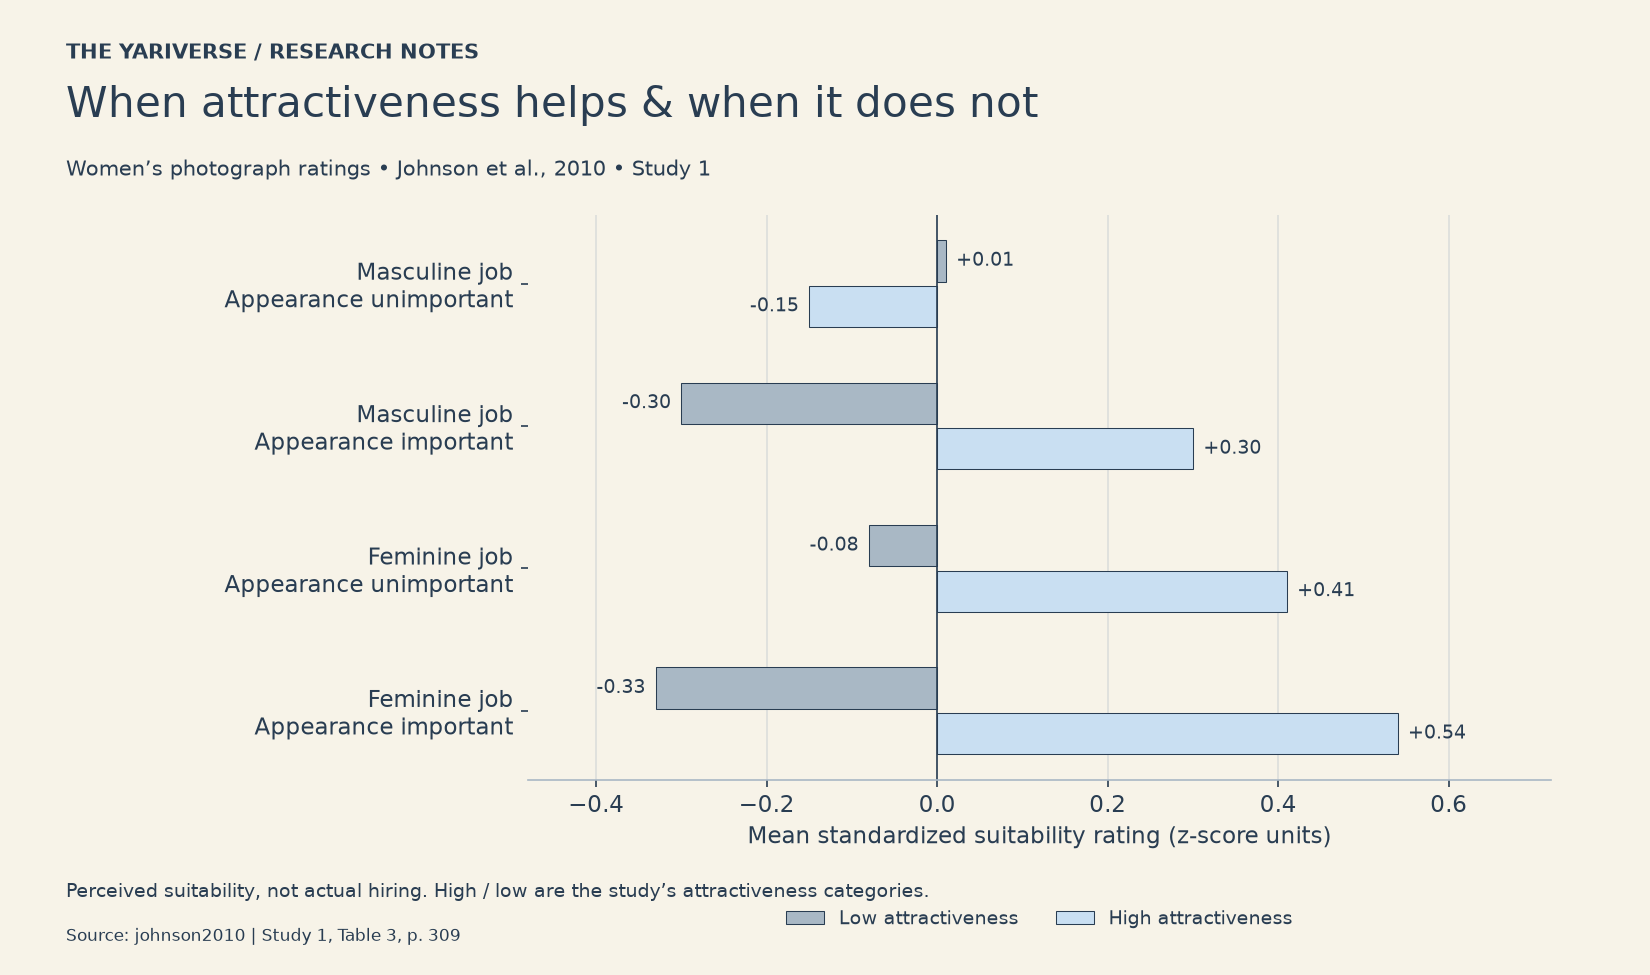

In [8]:
fig,ax=canvas('When attractiveness helps & when it does not','Women’s photograph ratings • Johnson et al., 2010 • Study 1')
y=np.arange(4)
for a,offset,color in [('Low',-.16,P['dusty']),('High',.16,P['baby'])]:
    vals=ratings.query("sex=='Female' and attractiveness==@a").set_index('context').loc[contexts,'mean']
    bars=ax.barh(y+offset,vals,height=.29,color=color,edgecolor=P['slate'],linewidth=.5,label=a+' attractiveness')
    ax.bar_label(bars,fmt='%+.2f',padding=5,fontsize=9,color=P['slate'])
ax.set_yticks(y,labels); ax.invert_yaxis(); ax.axvline(0,color=P['slate'],lw=.8)
ax.set_xlim(-.48,.72); ax.set_xlabel('Mean standardized suitability rating (z-score units)')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.20),ncol=2,fontsize=9)
finish(fig,'chart_01_women_suitability','johnson2010','Perceived suitability, not actual hiring. High / low are the study’s attractiveness categories.')


### 2. Compare the attractiveness difference by gender
The single negative contrast is −0.16 for women in masculine/appearance-unimportant jobs. No pooled effect or significance test is computed across the repeated contexts.

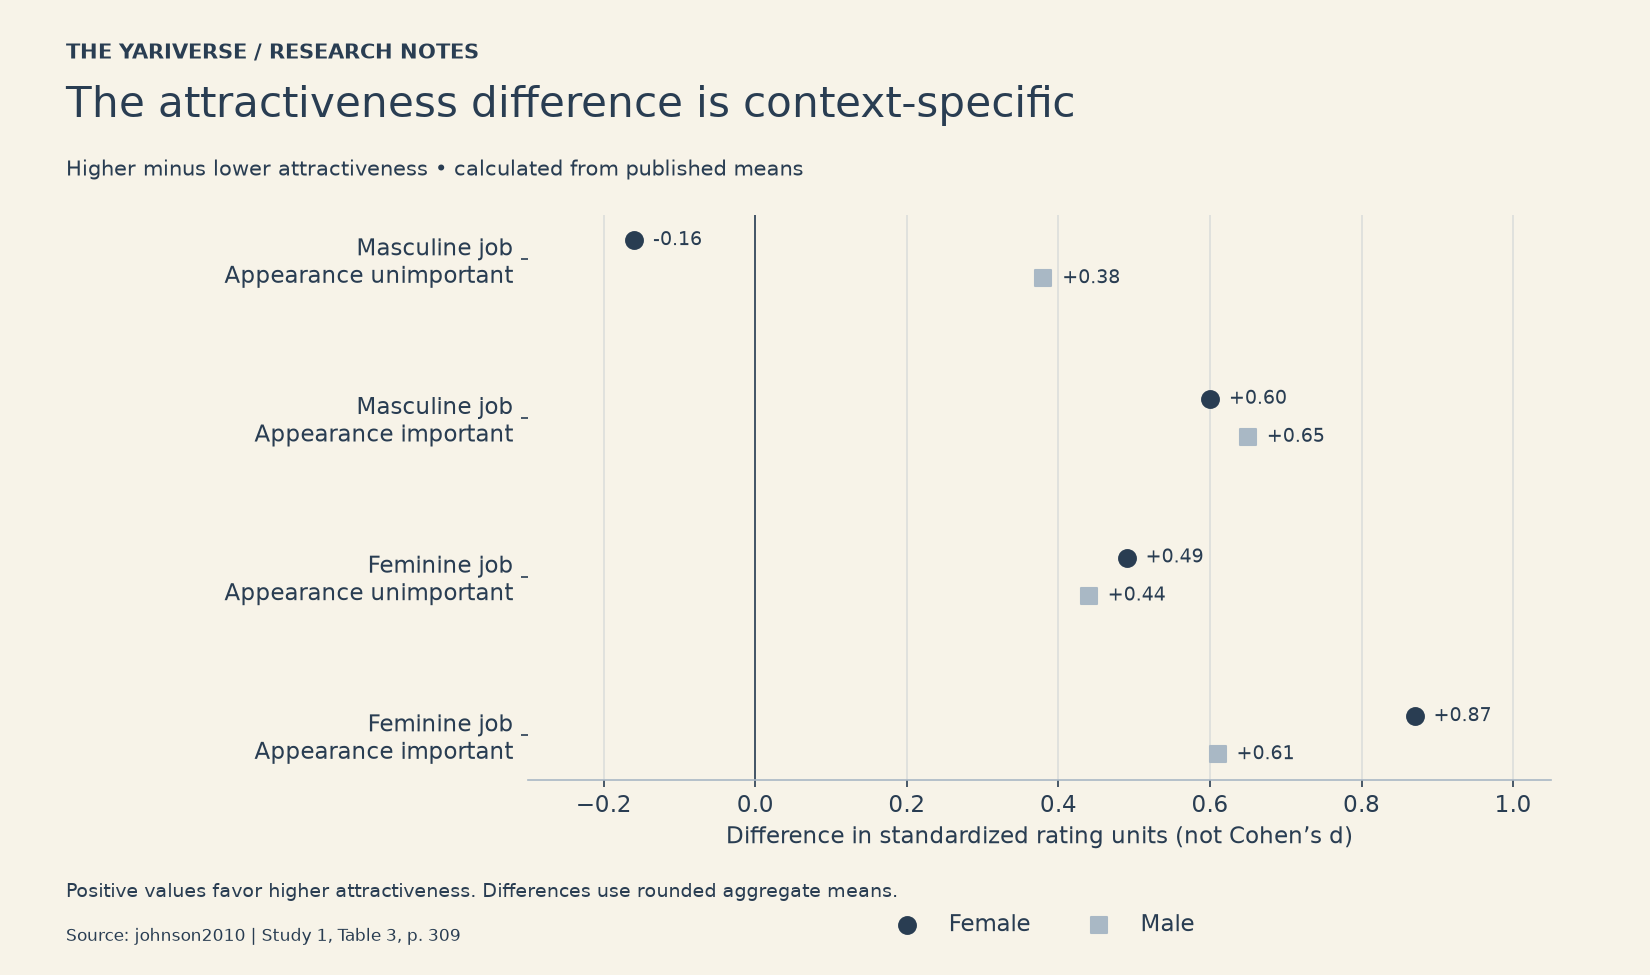

In [9]:
fig,ax=canvas('The attractiveness difference is context-specific','Higher minus lower attractiveness • calculated from published means')
y=np.arange(4)
for sex,offset,color,marker in [('Female',-.12,P['slate'],'o'),('Male',.12,P['dusty'],'s')]:
    v=contrasts.query('sex==@sex').set_index('context').loc[contexts,'high_minus_low']
    ax.scatter(v,y+offset,c=color,marker=marker,s=65,label=sex)
    for yy,value in zip(y+offset,v):ax.text(value+.025,yy,f'{value:+.2f}',va='center',fontsize=9)
ax.axvline(0,color=P['slate'],lw=.8); ax.set_yticks(y,labels); ax.invert_yaxis()
ax.set_xlim(-.3,1.05); ax.set_xlabel('Difference in standardized rating units (not Cohen’s d)')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.20),ncol=2)
finish(fig,'chart_02_attractiveness_contrasts','johnson2010','Positive values favor higher attractiveness. Differences use rounded aggregate means.')


### 3. Scientists’ reported experiences
These are self-reports across scientists of all genders, not proof of surveillance or women-specific hiring outcomes.

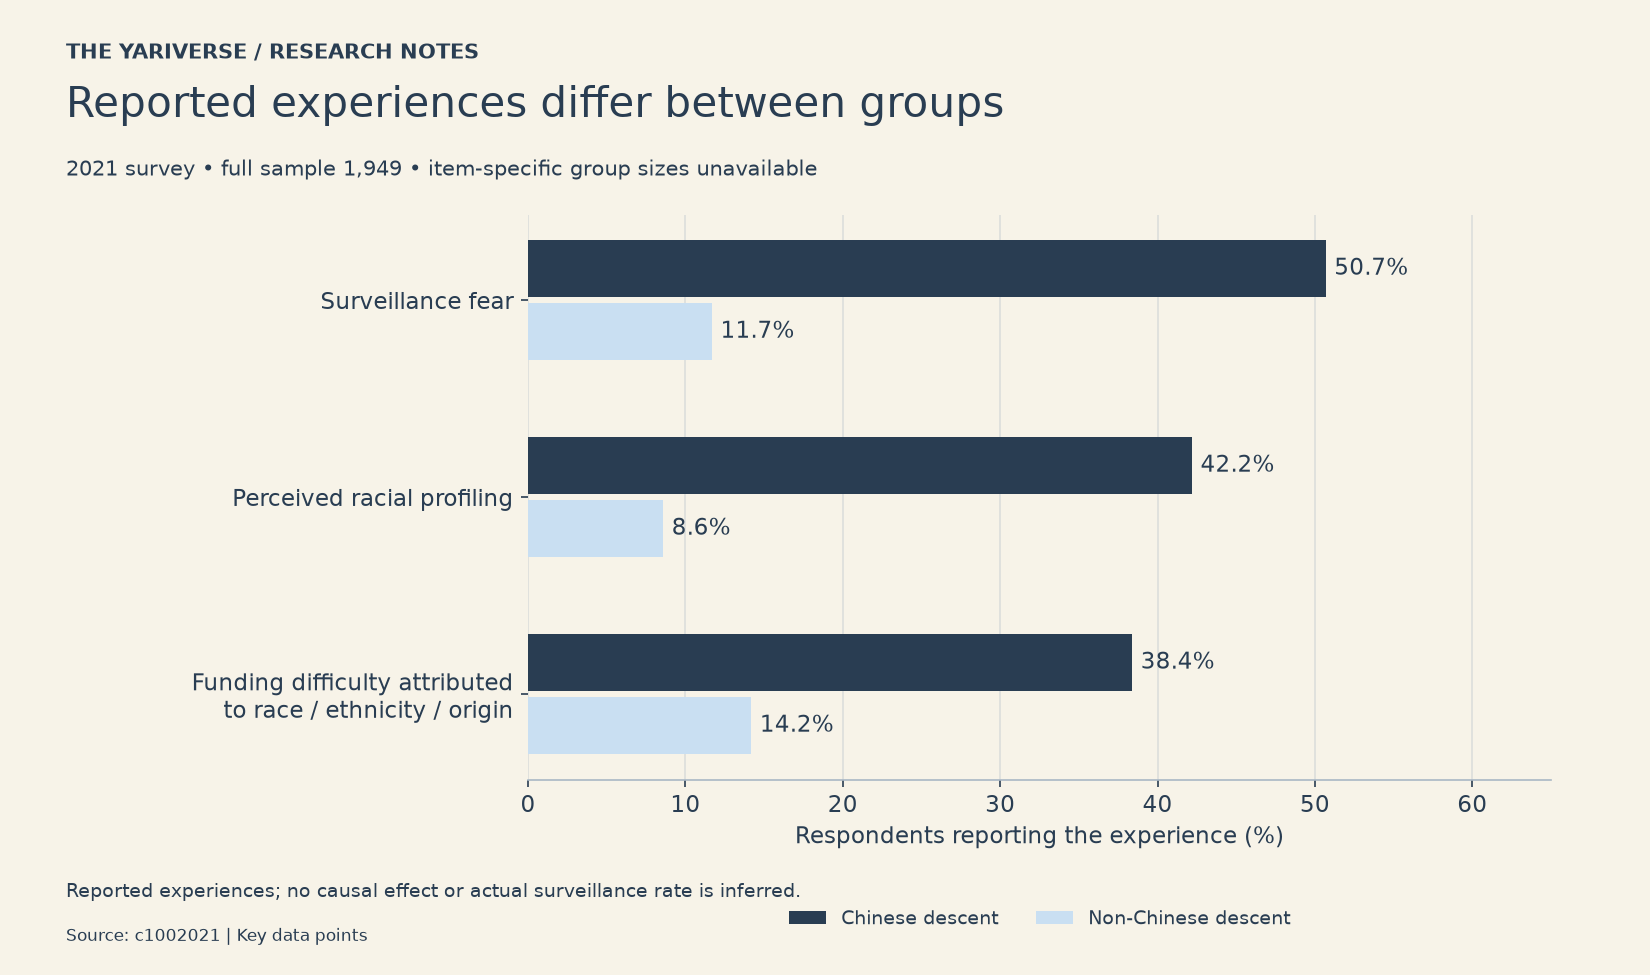

In [10]:
fig,ax=canvas('Reported experiences differ between groups','2021 survey • full sample 1,949 • item-specific group sizes unavailable')
y=np.arange(3)
for col,off,color,label in [('chinese_descent_pct',-.16,P['slate'],'Chinese descent'),('non_chinese_descent_pct',.16,P['baby'],'Non-Chinese descent')]:
    b=ax.barh(y+off,survey[col],height=.29,color=color,label=label)
    ax.bar_label(b,fmt='%.1f%%',padding=4,color=P['slate'])
ax.set_yticks(y,['Surveillance fear','Perceived racial profiling','Funding difficulty attributed\nto race / ethnicity / origin']);ax.invert_yaxis()
ax.set_xlim(0,65);ax.set_xlabel('Respondents reporting the experience (%)')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.20),ncol=2,fontsize=9)
finish(fig,'chart_03_survey_rates','c1002021','Reported experiences; no causal effect or actual surveillance rate is inferred.')


### 4. Absolute and relative survey differences
The largest absolute gap is 39.0 percentage points for surveillance fear. Its reported-percentage ratio is 4.33; this is not a causal risk estimate.

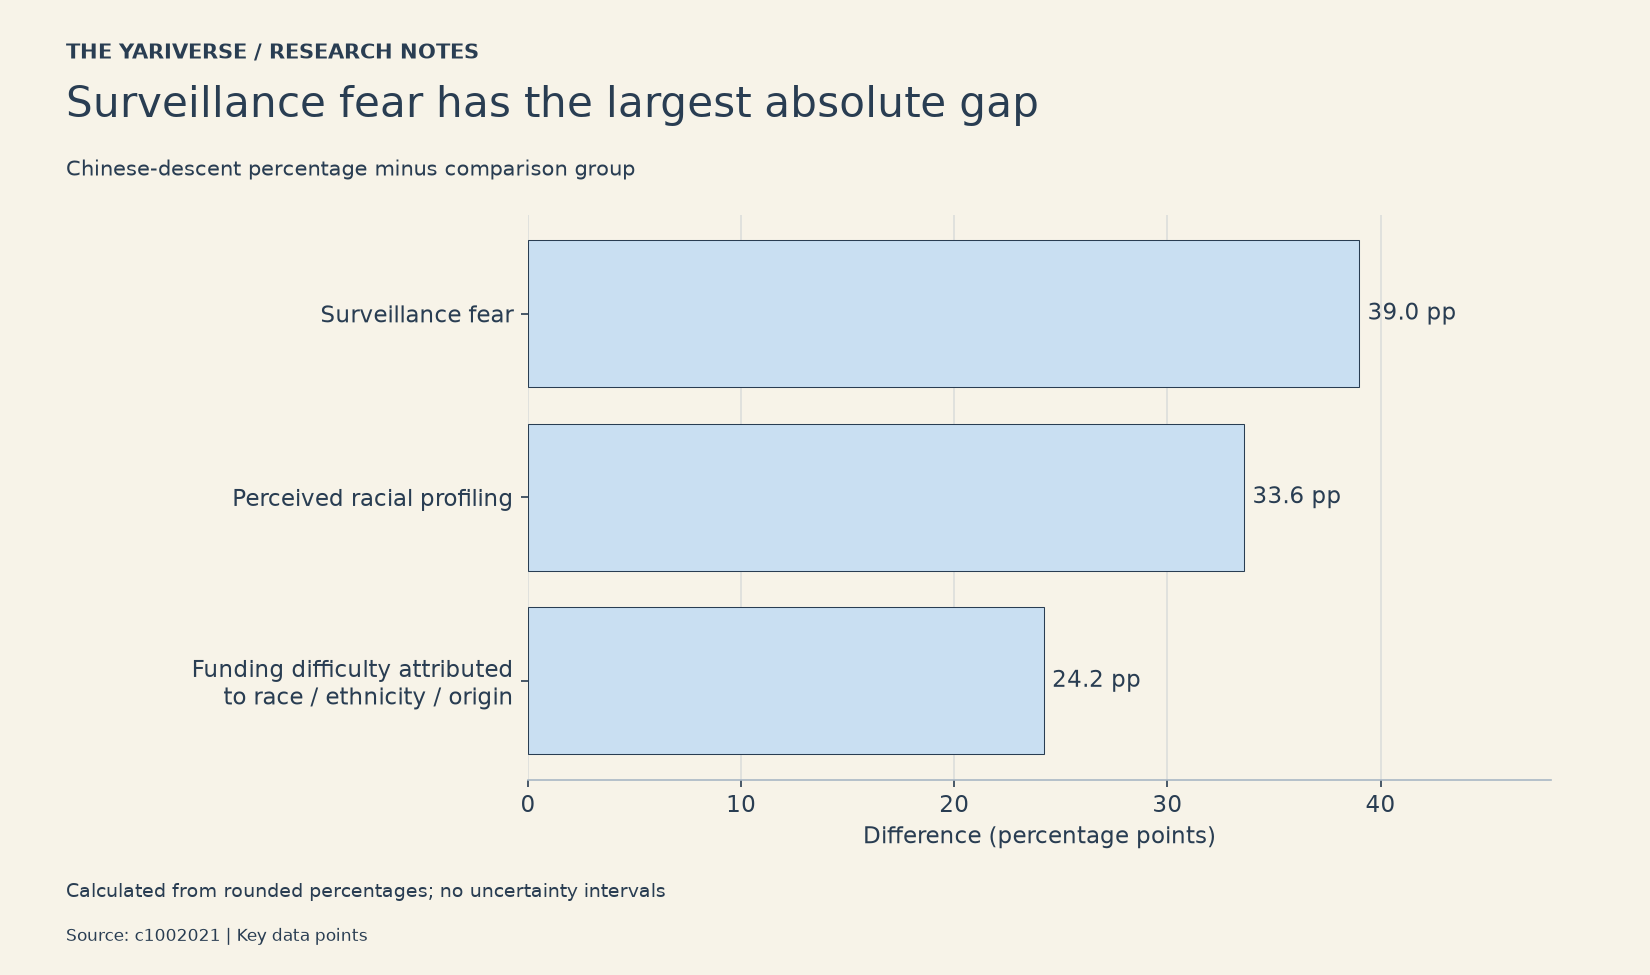

In [14]:
fig, ax = canvas(
    'Surveillance fear has the largest absolute gap',
    'Chinese-descent percentage minus comparison group'
)

# Create horizontal bars
y_positions = np.arange(len(survey))

b = ax.barh(
    y_positions,
    survey['gap_pp'],
    color=P['baby'],
    edgecolor=P['slate'],
    linewidth=0.5
)

# Labels and formatting
ax.bar_label(b, fmt='%.1f pp', padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 48)

# Fix tick positions before assigning labels
ax.set_yticks(y_positions)

ax.set_yticklabels([
    'Surveillance fear',
    'Perceived racial profiling',
    'Funding difficulty attributed\n'
    'to race / ethnicity / origin'
])

ax.set_xlabel('Difference (percentage points)')

finish(
    fig,
    'chart_04_survey_gaps',
    'c1002021',
    'Calculated from rounded percentages; no uncertainty intervals'
)

### 5. Themes counted across qualitative studies
Counts overlap. They measure coverage in the review, not population prevalence.

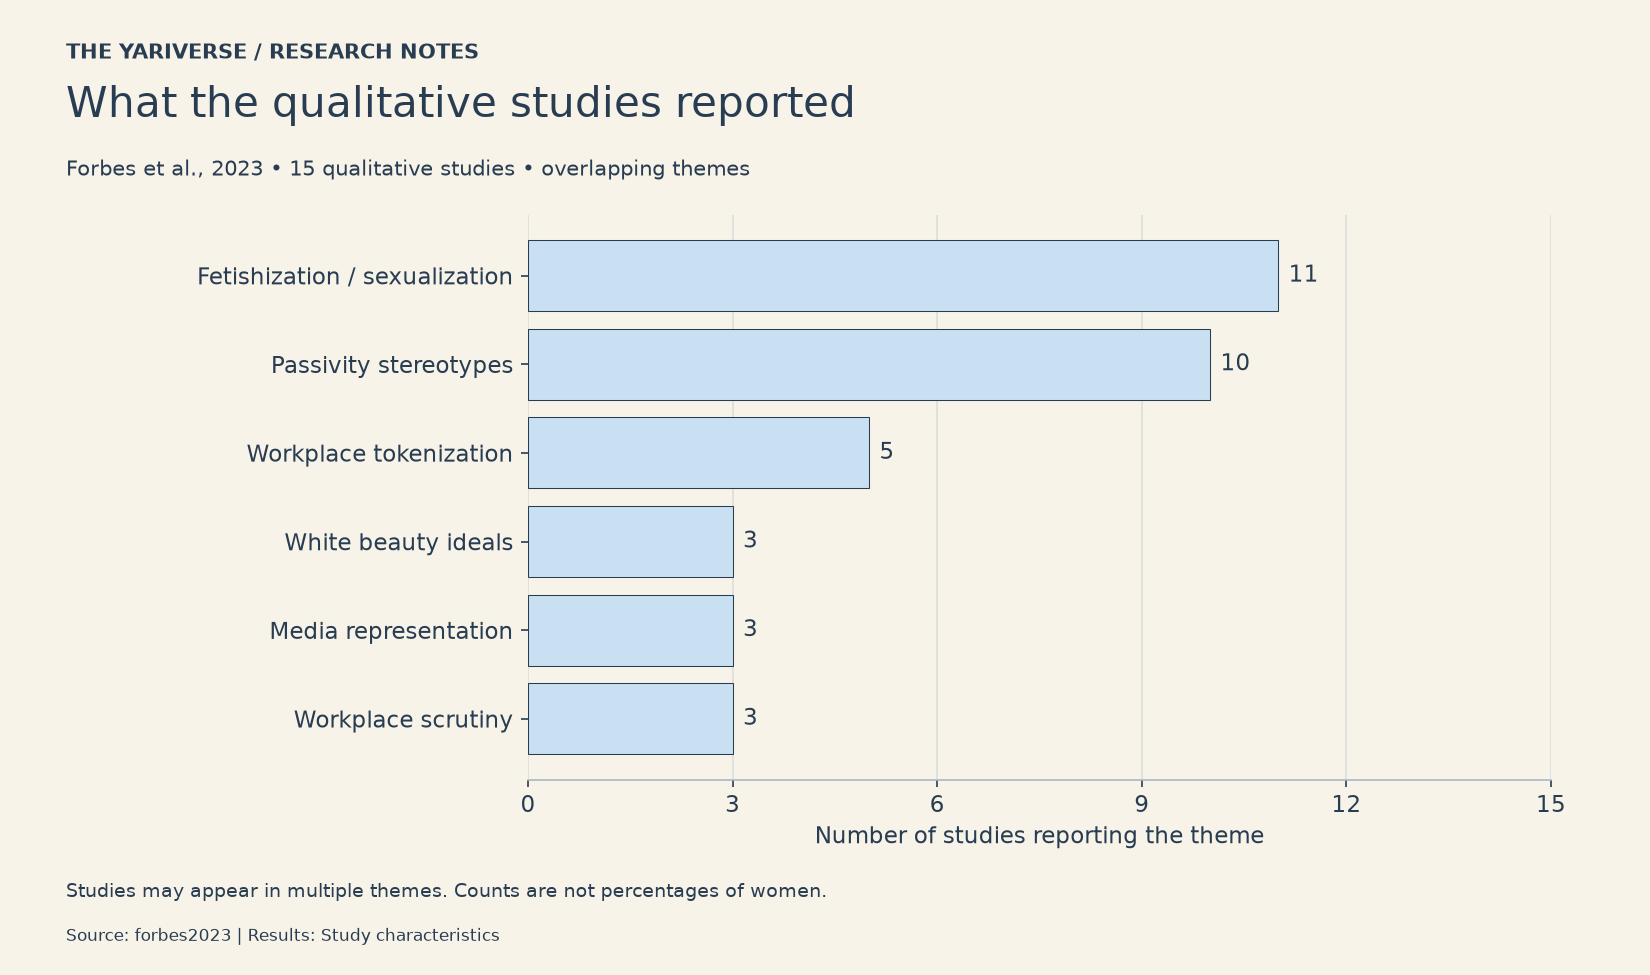

In [12]:
fig,ax=canvas('What the qualitative studies reported','Forbes et al., 2023 • 15 qualitative studies • overlapping themes')
b=ax.barh(themes.theme,themes.studies,color=P['baby'],edgecolor=P['slate'],linewidth=.5)
ax.bar_label(b,fmt='%d',padding=5);ax.invert_yaxis();ax.set_xlim(0,15);ax.set_xticks(range(0,16,3))
ax.set_xlabel('Number of studies reporting the theme')
finish(fig,'chart_05_review_themes','forbes2023','Studies may appear in multiple themes. Counts are not percentages of women.')


### 6. Composition of the evidence base

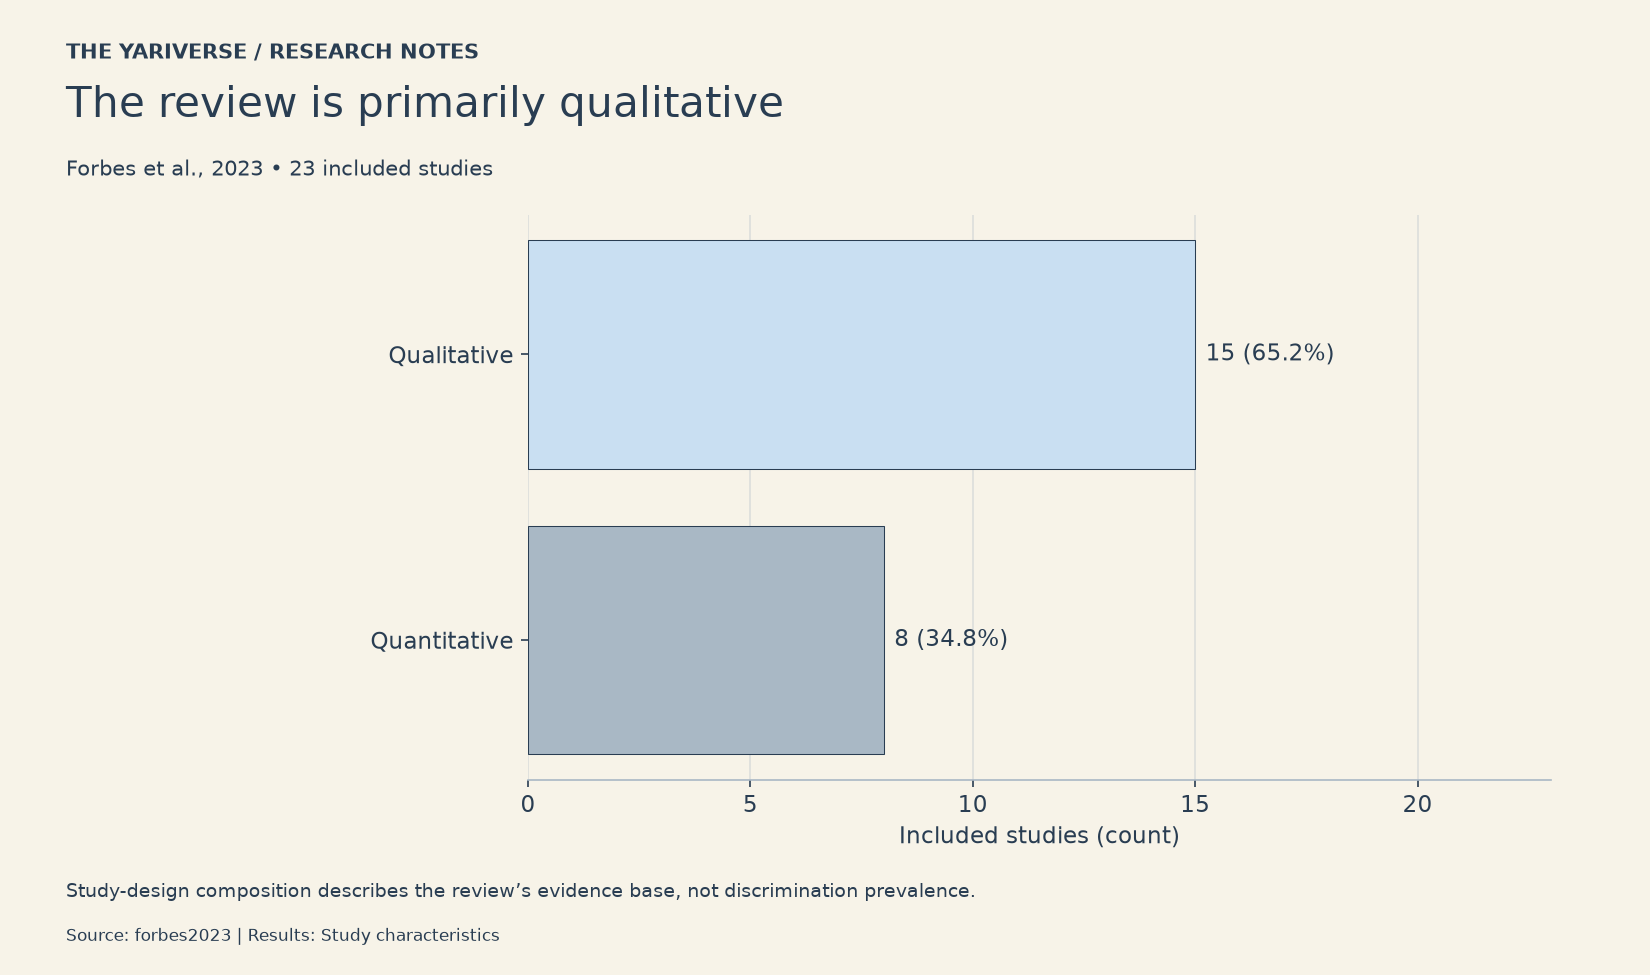

In [13]:
fig,ax=canvas('The review is primarily qualitative','Forbes et al., 2023 • 23 included studies')
b=ax.barh(review.design,review.studies,color=[P['baby'],P['dusty']],edgecolor=P['slate'],linewidth=.5)
ax.bar_label(b,labels=[f'{n} ({s:.1f}%)' for n,s in zip(review.studies,review.share_pct)],padding=5)
ax.invert_yaxis();ax.set_xlim(0,23);ax.set_xlabel('Included studies (count)')
finish(fig,'chart_06_evidence_composition','forbes2023','Study-design composition describes the review’s evidence base, not discrimination prevalence.')
